# Análise de viagens a serviço do Governo Federal

**Autora:** Camila Gomes dos Santos

Este projeto analisa os gastos e as características das viagens a serviço, utilizando os dados de 2025 disponibilizados para o projeto.

As análises utilizam as tabelas SILVER, após a transformação e a validação dos dados.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from banco import conectar

print("Bibliotecas importadas com sucesso!")

Bibliotecas importadas com sucesso!


In [2]:
conexao = conectar()

try:
    cursor = conexao.cursor()
    cursor.execute("SELECT COUNT(*) FROM silver_viagem;")

    quantidade = cursor.fetchone()[0]
    print(f"Conexão realizada! Total de viagens: {quantidade:,}")

    cursor.close()

finally:
    conexao.close()

Conexão realizada! Total de viagens: 341,860


## 1. Órgãos superiores com maior gasto total

Quais são os cinco órgãos superiores com maior gasto total em viagens na base analisada?

O valor total considera diárias, passagens e outros gastos, descontando as devoluções.

In [3]:
consulta_orgaos = """
SELECT
    cod_orgao_superior,
    nome_orgao_superior,
    COUNT(*) AS quantidade_viagens,
    SUM(valor_total) AS gasto_total
FROM silver_viagem
GROUP BY cod_orgao_superior, nome_orgao_superior
ORDER BY gasto_total DESC NULLS LAST
LIMIT 5;
"""

conexao = conectar()

try:
    cursor = conexao.cursor()
    cursor.execute(consulta_orgaos)

    colunas = [coluna[0] for coluna in cursor.description]
    df_orgaos = pd.DataFrame(cursor.fetchall(), columns=colunas)

    cursor.close()

finally:
    conexao.close()

df_orgaos

,cod_orgao_superior,nome_orgao_superior,quantidade_viagens,gasto_total
0,30000,Ministério da Justiça e Segurança Pública,75742,486933121.65
1,52000,Ministério da Defesa,61912,156070304.49
2,26000,Ministério da Educação,65295,111291349.34
3,44000,Ministério do Meio Ambiente e Mudança do Clima,19413,49697710.16
4,33000,Ministério da Previdência Social,8190,40417309.06


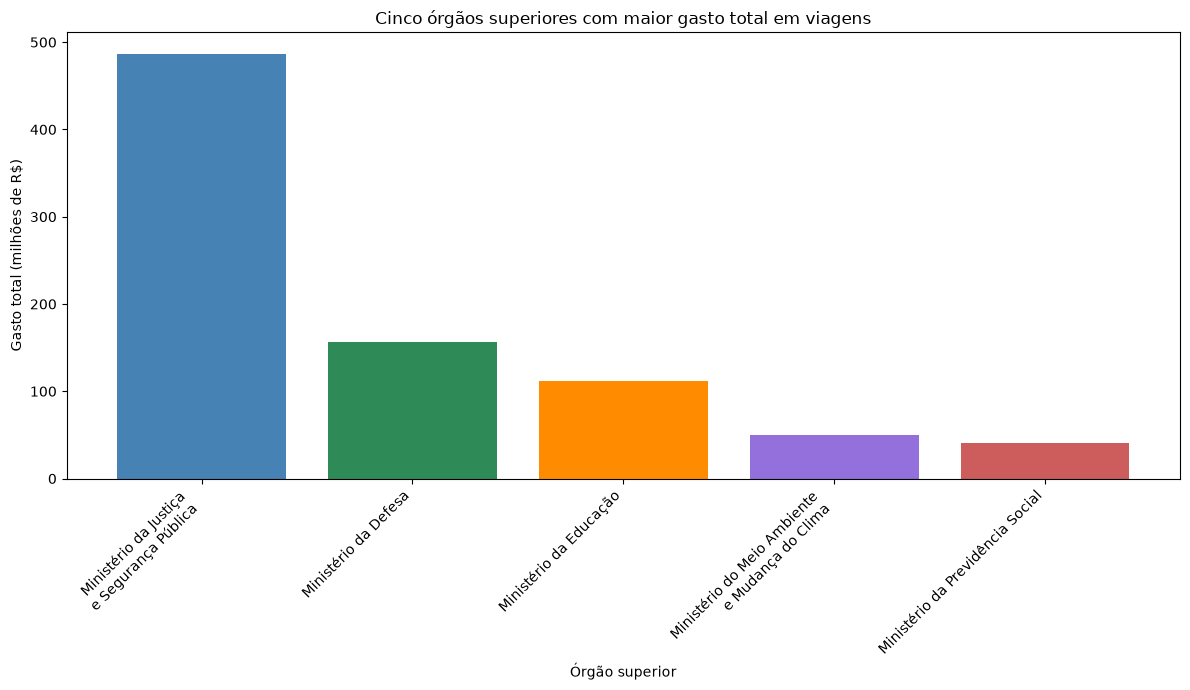

In [4]:
cores = ["steelblue", "seagreen", "darkorange", "mediumpurple", "indianred"]

nomes_grafico = df_orgaos["nome_orgao_superior"].replace({
    "Ministério da Justiça e Segurança Pública":
        "Ministério da Justiça\ne Segurança Pública",
    "Ministério do Meio Ambiente e Mudança do Clima":
        "Ministério do Meio Ambiente\ne Mudança do Clima"
})

plt.figure(figsize=(12, 7))

plt.bar(
    nomes_grafico,
    df_orgaos["gasto_total"].astype(float) / 1_000_000,
    color=cores
)

plt.title("Cinco órgãos superiores com maior gasto total em viagens")
plt.xlabel("Órgão superior")
plt.ylabel("Gasto total (milhões de R$)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Interpretação

O Ministério da Justiça e Segurança Pública teve o maior gasto com
viagens, cerca de R$ 486,93 milhões. Também foi o órgão com mais
viagens entre os cinco apresentados, com 75.742 registros.

Comparando a Defesa com a Educação, percebi que a Educação teve
mais viagens, mas gastou menos. Isso mostra que não basta olhar
apenas a quantidade de viagens para entender os gastos.

Para entender melhor essa diferença, seria preciso analisar o custo
médio, a duração e os destinos das viagens.

## 2. Meios de transporte mais utilizados

Nesta análise, vou verificar quais meios de transporte aparecem
com mais frequência nos trechos das viagens.

A contagem considera os trechos registrados, pois uma mesma viagem
pode ter mais de um trecho.

In [5]:
consulta_transportes = """
SELECT
    meio_transporte,
    COUNT(*) AS quantidade_trechos
FROM silver_trecho
GROUP BY meio_transporte
ORDER BY quantidade_trechos DESC;
"""

conexao = conectar()

try:
    cursor = conexao.cursor()
    cursor.execute(consulta_transportes)

    colunas = [coluna[0] for coluna in cursor.description]
    df_transportes = pd.DataFrame(cursor.fetchall(), columns=colunas)

    cursor.close()

finally:
    conexao.close()

df_transportes

,meio_transporte,quantidade_trechos
0,Veículo Oficial,386424
1,Aéreo,232666
2,Rodoviário,64970
3,Veículo Próprio,42846
4,Inválido,26659
5,Fluvial,8429
6,Ferroviário,874
7,Marítimo,481


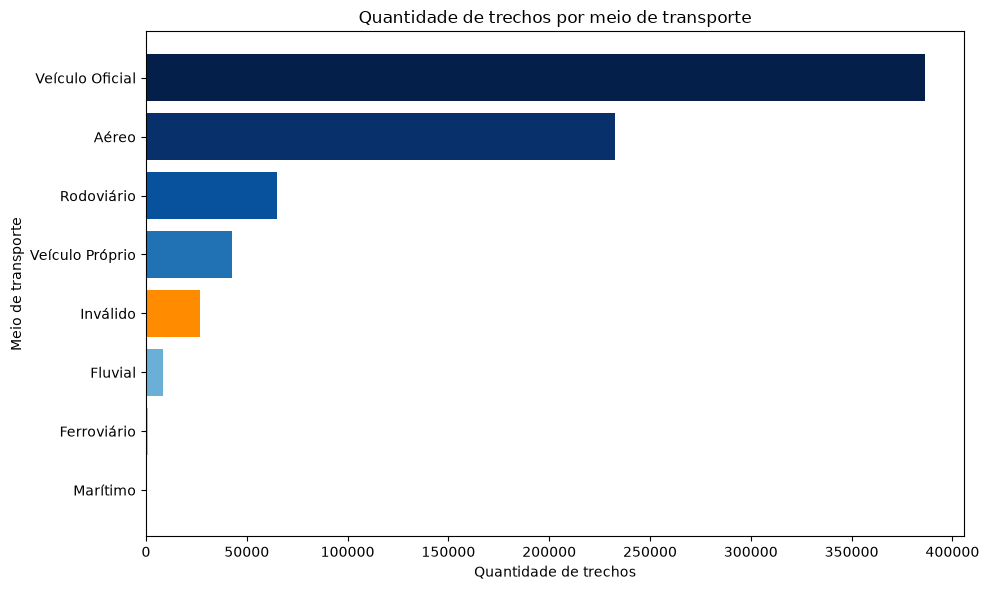

In [6]:
transportes_grafico = df_transportes.sort_values("quantidade_trechos")

cores_transportes = [
    "#BDD7E7",
    "#9ECAE1",
    "#6BAED6",
    "#4292C6",
    "#2171B5",
    "#08519C",
    "#08306B",
    "#041F4A"
]

cores_transportes = [
    "darkorange" if transporte == "Inválido" else cor
    for transporte, cor in zip(
        transportes_grafico["meio_transporte"],
        cores_transportes
    )
]

plt.figure(figsize=(10, 6))

plt.barh(
    transportes_grafico["meio_transporte"],
    transportes_grafico["quantidade_trechos"],
    color=cores_transportes
)

plt.title("Quantidade de trechos por meio de transporte")
plt.xlabel("Quantidade de trechos")
plt.ylabel("Meio de transporte")
plt.tight_layout()
plt.show()

### Interpretação

O veículo oficial foi o transporte mais registrado, com 386.424
trechos, seguido pelo aéreo, com 232.666.

Também identifiquei 26.659 trechos classificados como “Inválido”,
destacados em laranja. Nesses registros, não é possível saber qual
transporte foi utilizado. Mantive essa categoria na análise para
mostrar essa limitação dos dados.

A contagem considera os trechos, e uma mesma viagem pode aparecer
mais de uma vez por ter vários deslocamentos.

## 3. Valor médio por tipo de pagamento

Nesta análise, vou comparar o valor médio dos pagamentos de cada
tipo registrado na base.

A média considera cada registro de pagamento, e não o total por viagem.

In [7]:
consulta_pagamentos = """
SELECT
    tipo_pagamento,
    COUNT(*) AS quantidade_pagamentos,
    ROUND(AVG(valor), 2) AS valor_medio
FROM silver_pagamento
GROUP BY tipo_pagamento
ORDER BY valor_medio DESC NULLS LAST;
"""

conexao = conectar()

try:
    cursor = conexao.cursor()
    cursor.execute(consulta_pagamentos)

    colunas = [coluna[0] for coluna in cursor.description]
    df_pagamentos = pd.DataFrame(cursor.fetchall(), columns=colunas)

    cursor.close()

finally:
    conexao.close()

df_pagamentos

,tipo_pagamento,quantidade_pagamentos,valor_medio
0,DIÁRIAS,401463,2078.28
1,PASSAGEM,188985,1878.34
2,Serviço correlato: seguro,4894,447.51
3,RESTITUIÇÃO,11574,245.70


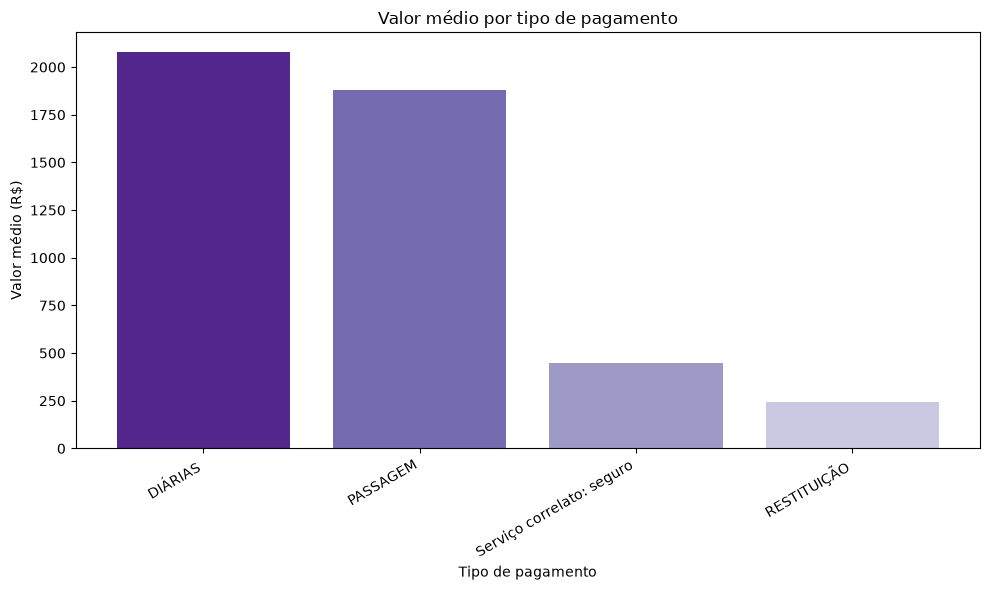

In [8]:
cores_pagamentos = ["#54278F", "#756BB1", "#9E9AC8", "#CBC9E2"]

plt.figure(figsize=(10, 6))

plt.bar(
    df_pagamentos["tipo_pagamento"],
    df_pagamentos["valor_medio"].astype(float),
    color=cores_pagamentos
)

plt.title("Valor médio por tipo de pagamento")
plt.xlabel("Tipo de pagamento")
plt.ylabel("Valor médio (R$)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## Camada GOLD

Nesta etapa, vou cruzar os dados de viagens e pagamentos para
organizar os valores por órgão superior e tipo de pagamento.

Esse resumo será utilizado nas próximas análises.

In [9]:
sql_gold_pagamentos = """
DROP TABLE IF EXISTS gold_pagamentos_orgao_tipo;

CREATE TABLE gold_pagamentos_orgao_tipo AS
SELECT
    v.cod_orgao_superior,
    v.nome_orgao_superior,
    p.tipo_pagamento,
    COUNT(*) AS quantidade_pagamentos,
    COUNT(DISTINCT p.id_viagem) AS quantidade_viagens,
    SUM(p.valor) AS valor_total
FROM silver_pagamento AS p
JOIN silver_viagem AS v
    ON p.id_viagem = v.id_viagem
GROUP BY
    v.cod_orgao_superior,
    v.nome_orgao_superior,
    p.tipo_pagamento;
"""

conexao = conectar()

try:
    cursor = conexao.cursor()
    cursor.execute(sql_gold_pagamentos)
    conexao.commit()
    cursor.close()

    print("Tabela GOLD de pagamentos criada com sucesso!")

except Exception:
    conexao.rollback()
    raise

finally:
    conexao.close()

Tabela GOLD de pagamentos criada com sucesso!


### Resumo dos trechos

Vou criar uma view para consultar a quantidade de trechos por órgão,
UF de destino e meio de transporte.

A view consulta os dados atuais das tabelas SILVER sempre que é utilizada.

In [10]:
sql_view_trechos = """
CREATE OR REPLACE VIEW vw_gold_trechos AS
SELECT
    v.cod_orgao_superior,
    v.nome_orgao_superior,
    t.destino_uf,
    t.meio_transporte,
    COUNT(*) AS quantidade_trechos
FROM silver_trecho AS t
JOIN silver_viagem AS v
    ON t.id_viagem = v.id_viagem
GROUP BY
    v.cod_orgao_superior,
    v.nome_orgao_superior,
    t.destino_uf,
    t.meio_transporte;
"""

conexao = conectar()

try:
    cursor = conexao.cursor()
    cursor.execute(sql_view_trechos)
    conexao.commit()
    cursor.close()

    print("View GOLD de trechos criada com sucesso!")

except Exception:
    conexao.rollback()
    raise

finally:
    conexao.close()

View GOLD de trechos criada com sucesso!


## 4. Participação dos tipos de pagamento no valor total

Vou utilizar a tabela GOLD para comparar quanto cada tipo de
pagamento representa na soma dos valores registrados.

A restituição será apresentada como uma categoria separada,
conforme está na base. Essa soma não representa o gasto líquido
das viagens.

In [11]:
consulta_participacao = """
SELECT
    tipo_pagamento,
    SUM(valor_total) AS valor_total
FROM gold_pagamentos_orgao_tipo
GROUP BY tipo_pagamento
ORDER BY valor_total DESC;
"""

conexao = conectar()

try:
    cursor = conexao.cursor()
    cursor.execute(consulta_participacao)

    colunas = [coluna[0] for coluna in cursor.description]
    df_participacao = pd.DataFrame(cursor.fetchall(), columns=colunas)

    cursor.close()

finally:
    conexao.close()

df_participacao["percentual"] = (
    df_participacao["valor_total"].astype(float)
    / df_participacao["valor_total"].astype(float).sum()
    * 100
).round(2)

df_participacao

,tipo_pagamento,valor_total,percentual
0,DIÁRIAS,834352643.52,69.86
1,PASSAGEM,354978915.13,29.72
2,RESTITUIÇÃO,2843762.01,0.24
3,Serviço correlato: seguro,2190136.71,0.18


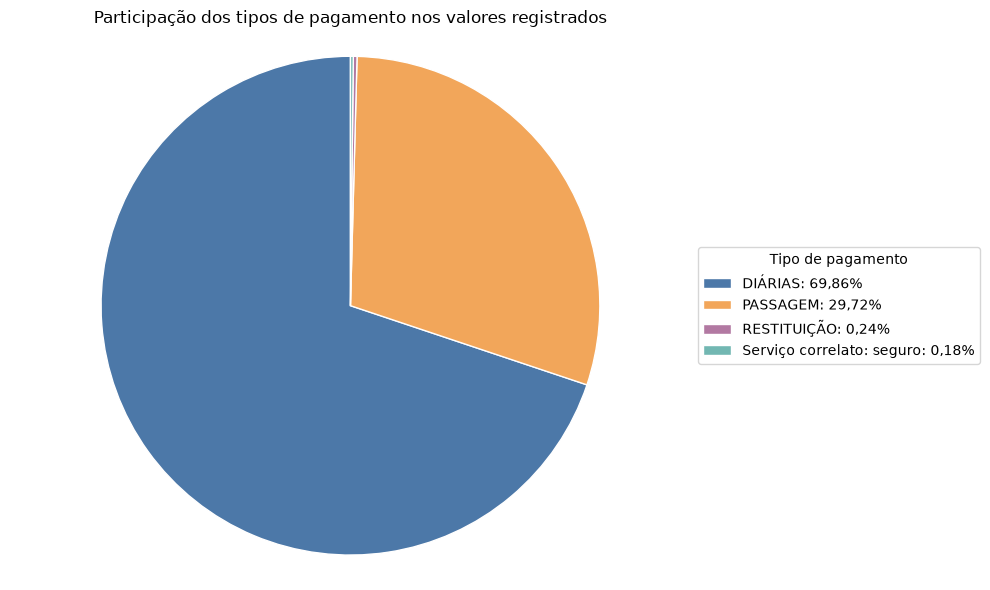

In [12]:
cores_participacao = [
    "#4C78A8",  # Azul: diárias
    "#F2A65A",  # Laranja suave: passagens
    "#B279A2",  # Malva: restituição
    "#72B7B2"   # Verde suave: seguro
]

legendas = [
    f"{tipo}: {percentual:.2f}%".replace(".", ",")
    for tipo, percentual in zip(
        df_participacao["tipo_pagamento"],
        df_participacao["percentual"]
    )
]

plt.figure(figsize=(10, 6))

plt.pie(
    df_participacao["valor_total"].astype(float),
    colors=cores_participacao,
    startangle=90,
    wedgeprops={"edgecolor": "white"}
)

plt.legend(
    legendas,
    title="Tipo de pagamento",
    loc="center left",
    bbox_to_anchor=(1, 0.5)
)

plt.title("Participação dos tipos de pagamento nos valores registrados")
plt.axis("equal")
plt.tight_layout()
plt.show()

### Interpretação

As diárias concentraram 69,86% dos valores registrados, seguidas pelas passagens, com 29,72%. Juntas, representam aproximadamente 99,58% da soma analisada.

A restituição e o seguro tiveram participações menores, de 0,24% e 0,18%, respectivamente.

A restituição foi mantida como uma categoria separada. Por isso, o gráfico mostra a distribuição dos valores registrados na tabela de pagamentos, e não o gasto líquido das viagens.

## 5. UFs de destino com mais trechos

Vou verificar quais são as cinco UFs que mais aparecem como destino
nos trechos registrados.

Os registros sem UF de destino ficam fora desse ranking. A contagem
considera os trechos, e não a quantidade de viagens diferentes.

In [13]:
consulta_destinos = """
SELECT
    destino_uf,
    SUM(quantidade_trechos) AS quantidade_trechos
FROM vw_gold_trechos
WHERE destino_uf IS NOT NULL
GROUP BY destino_uf
ORDER BY quantidade_trechos DESC, destino_uf
LIMIT 5;
"""

conexao = conectar()

try:
    cursor = conexao.cursor()
    cursor.execute(consulta_destinos)

    colunas = [coluna[0] for coluna in cursor.description]
    df_destinos = pd.DataFrame(cursor.fetchall(), columns=colunas)

    cursor.close()

finally:
    conexao.close()

df_destinos

,destino_uf,quantidade_trechos
0,São Paulo,82722
1,Distrito Federal,79962
2,Minas Gerais,50965
3,Rio de Janeiro,44197
4,Paraná,42603


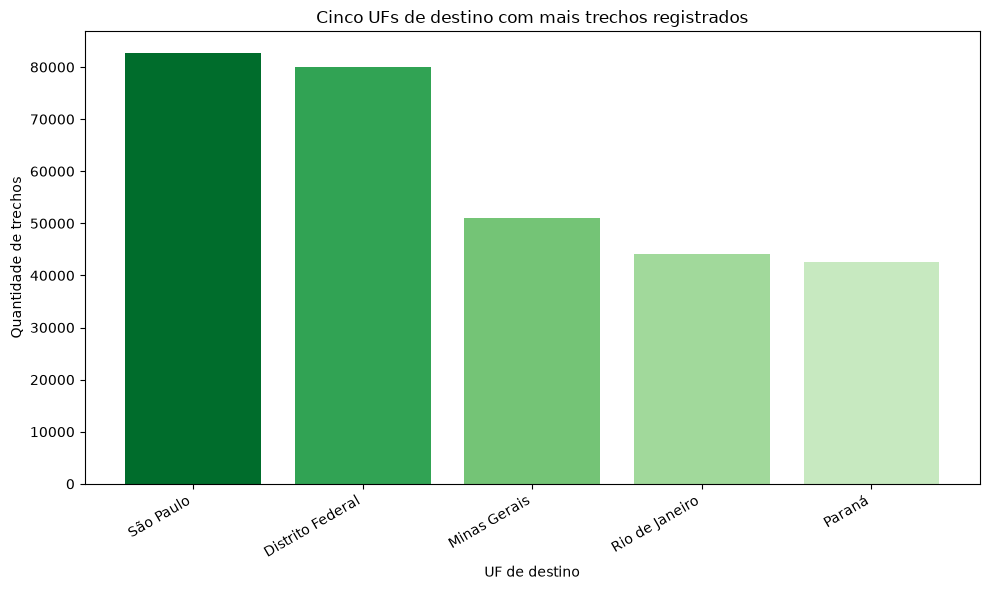

In [14]:
cores_destinos = [
    "#006D2C",
    "#31A354",
    "#74C476",
    "#A1D99B",
    "#C7E9C0"
]

plt.figure(figsize=(10, 6))

plt.bar(
    df_destinos["destino_uf"],
    df_destinos["quantidade_trechos"].astype(int),
    color=cores_destinos
)

plt.title("Cinco UFs de destino com mais trechos registrados")
plt.xlabel("UF de destino")
plt.ylabel("Quantidade de trechos")
plt.xticks(rotation=30, ha="right")

plt.tight_layout()
plt.show()

### Interpretação

São Paulo foi a UF de destino com mais trechos registrados, com 82.722, seguido pelo Distrito Federal, com 79.962.

Minas Gerais, Rio de Janeiro e Paraná completaram os cinco primeiros lugares. São Paulo e Distrito Federal tiveram quantidades próximas e ficaram acima dos demais apresentados.

Esse resultado mostra a frequência dos destinos nos trechos. Uma mesma viagem pode ter vários trechos, inclusive de retorno, por isso essa contagem não representa viagens diferentes. Os registros sem UF de destino ficaram fora do ranking.

## 6. Quais órgãos têm mais trechos com meio de transporte registrado como “Inválido”?

Nesta análise, utilizo a visão GOLD para identificar os cinco órgãos com mais trechos nessa categoria.

In [15]:
sql_invalidos = """
SELECT
    cod_orgao_superior,
    nome_orgao_superior,
    SUM(quantidade_trechos) AS quantidade_trechos_invalidos
FROM vw_gold_trechos
WHERE meio_transporte = 'Inválido'
GROUP BY cod_orgao_superior, nome_orgao_superior
ORDER BY quantidade_trechos_invalidos DESC, nome_orgao_superior
LIMIT 5;
"""

conexao = conectar()

try:
    cursor = conexao.cursor()
    cursor.execute(sql_invalidos)

    colunas = [coluna[0] for coluna in cursor.description]

    df_invalidos = pd.DataFrame(
        cursor.fetchall(),
        columns=colunas
    )

    cursor.close()

finally:
    conexao.close()

df_invalidos

,cod_orgao_superior,nome_orgao_superior,quantidade_trechos_invalidos
0,52000,Ministério da Defesa,9374
1,30000,Ministério da Justiça e Segurança Pública,6110
2,26000,Ministério da Educação,4196
3,44000,Ministério do Meio Ambiente e Mudança do Clima,3934
4,49000,Ministério do Desenvolvimento Agrário e Agricu...,643


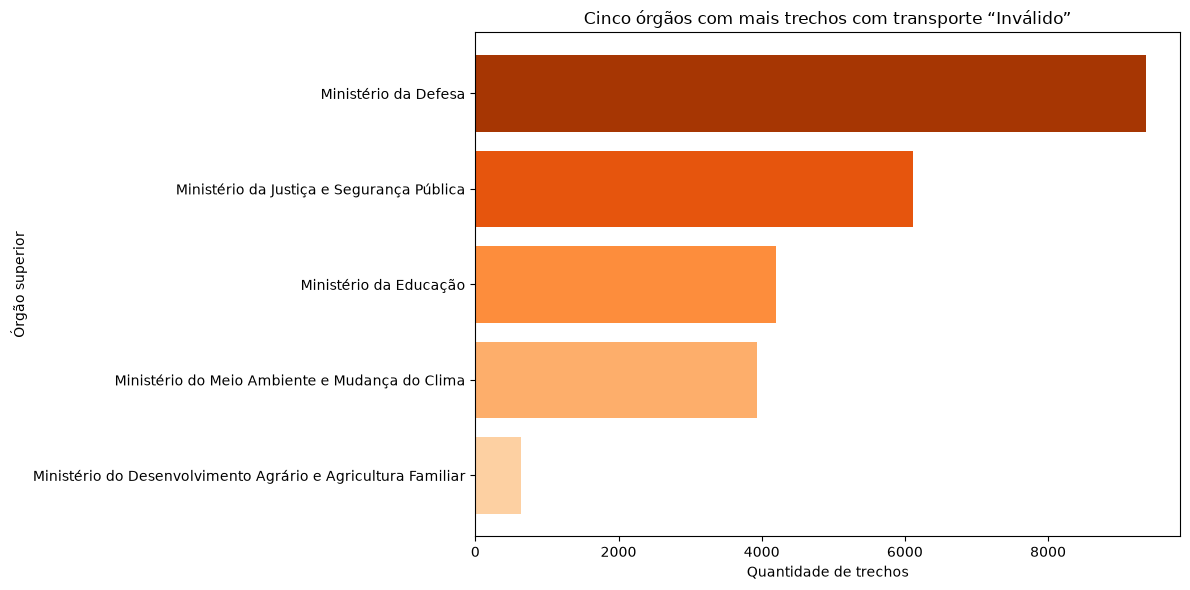

In [16]:
invalidos_grafico = df_invalidos.sort_values(
    "quantidade_trechos_invalidos"
)

plt.figure(figsize=(12, 6))

cores_invalidos = [
    "#FDD0A2",
    "#FDAE6B",
    "#FD8D3C",
    "#E6550D",
    "#A63603"
]

plt.barh(
    invalidos_grafico["nome_orgao_superior"],
    invalidos_grafico["quantidade_trechos_invalidos"].astype(int),
    color=cores_invalidos
)

plt.title("Cinco órgãos com mais trechos com transporte “Inválido”")
plt.xlabel("Quantidade de trechos")
plt.ylabel("Órgão superior")

plt.tight_layout()
plt.show()

O Ministério da Defesa apresentou a maior quantidade de trechos com meio de transporte registrado como “Inválido”, com 9.374 registros. Em seguida aparecem os ministérios da Justiça e Segurança Pública, com 6.110, da Educação, com 4.196, e do Meio Ambiente e Mudança do Clima, com 3.934.

Essa categoria limita a análise, pois não permite identificar o meio de transporte utilizado nesses trechos.

Os resultados mostram quantidades absolutas. Para avaliar quais órgãos têm maior proporção de registros “Inválido”, seria necessário comparar esses valores com o total de trechos de cada órgão.